<center>

$\Huge \textbf{Universidad Tecmilenio}$  
<p align="center">
  <img src="https://sic.cultura.gob.mx/images/135155" alt="Tecmilenio" width="200"/>
</p>

<hr style="height:3px; background-color:#0B6E4F; border:none;"/>


$\LARGE \textbf{Actividad 04-Modelos Preentrenados de Hugging Face}$  

$\Large \textit{Gestión de Proyectos de Inteligencia Artificial}$    

\begin{array}{rl}
\textbf{Docente:} & Dr. Eliskar Roger Altamirano Pariente \\[6pt]
\textbf{Alumnos:} & Emilio Páez García \\[6pt]
\textbf{Fecha de entrega:} & 11/10/2026
\end{array}

</center>

In [8]:
# Importaciones y configuración

import os
import time
import random
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns

from transformers import pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
from IPython.display import display

# Reproducibilidad
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Selección automática del dispositivo
device = 0 if torch.cuda.is_available() else -1

print("Versión de PyTorch:", torch.__version__)
print("Versión de CUDA disponible:", torch.version.cuda)
print("GPU disponible:", torch.cuda.is_available())
print("Dispositivo:", torch.cuda.get_device_name(0)
      if torch.cuda.is_available() else "CPU")


Versión de PyTorch: 2.12.1+cpu
Versión de CUDA disponible: None
GPU disponible: False
Dispositivo: CPU


In [9]:
# Carga y validación del dataset

RUTA_DATASET = "dataset_simulado_opiniones.csv"

df = pd.read_csv(RUTA_DATASET)

print("Dimensiones del dataset:", df.shape)
print("\nColumnas:", df.columns.tolist())

display(df.head())

Dimensiones del dataset: (250, 5)

Columnas: ['fecha', 'sentimiento', 'aspecto', 'comentario', 'calificacion']


,fecha,sentimiento,aspecto,comentario,calificacion
0,2025-11-08,positivo,tiempo de espera,"La tiempo de espera estuvo excelente, definiti...",4
1,2025-11-05,positivo,ambiente,"Muy buena ambiente, vale totalmente la pena. (...",4
2,2025-11-05,neutral,tiempo de espera,"La tiempo de espera estuvo bien, nada fuera de...",3
3,2025-11-05,negativo,comida,"La comida dejó mucho que desear, no volvería. ...",2
4,2025-11-14,positivo,comida,"La comida estuvo excelente, definitivamente vo...",5


In [ ]:
# Validación y limpieza de los datos

columnas_requeridas = {"comentario", "sentimiento"}

faltantes = columnas_requeridas - set(df.columns)

if faltantes:
    raise ValueError(f"Faltan columnas obligatorias: {faltantes}")

# Eliminar comentarios o etiquetas vacíos
df = df.dropna(subset=["comentario", "sentimiento"]).copy()
    
df["comentario"] = df["comentario"].astype(str).str.strip()
df["sentimiento"] = (
    df["sentimiento"].astype(str).str.strip().str.lower()
)

# Eliminar comentarios vacíos
df = df[df["comentario"] != ""].copy()

# Convertir las etiquetas originales a un formato uniforme
mapeo_reales = {
    "negativo": "NEG",
    "negative": "NEG",
    "neg": "NEG",
    "neutral": "NEU",
    "neu": "NEU",
    "positivo": "POS",
    "positive": "POS",
    "pos": "POS"
}

df["label_real"] = df["sentimiento"].map(mapeo_reales)

if df["label_real"].isna().any():
    etiquetas_desconocidas = df.loc[
        df["label_real"].isna(), "sentimiento"
    ].unique()
    raise ValueError(
        f"Etiquetas no reconocidas: {etiquetas_desconocidas}"
    )

if len(df) == 0:
    raise ValueError("No hay comentarios válidos para evaluar.")

df = df.reset_index(drop=True)

print("Comentarios válidos:", len(df))
print("\nDistribución de sentimientos:")
display(df["label_real"].value_counts().rename("cantidad").to_frame())

print("\nEjemplos:")
display(df[["comentario", "sentimiento", "label_real"]].head())


Comentarios válidos: 250

Distribución de sentimientos:


,cantidad
label_real,
POS,144
NEU,61
NEG,45



Ejemplos:


,comentario,sentimiento,label_real
0,"La tiempo de espera estuvo excelente, definiti...",positivo,POS
1,"Muy buena ambiente, vale totalmente la pena. (...",positivo,POS
2,"La tiempo de espera estuvo bien, nada fuera de...",neutral,NEU
3,"La comida dejó mucho que desear, no volvería. ...",negativo,NEG
4,"La comida estuvo excelente, definitivamente vo...",positivo,POS


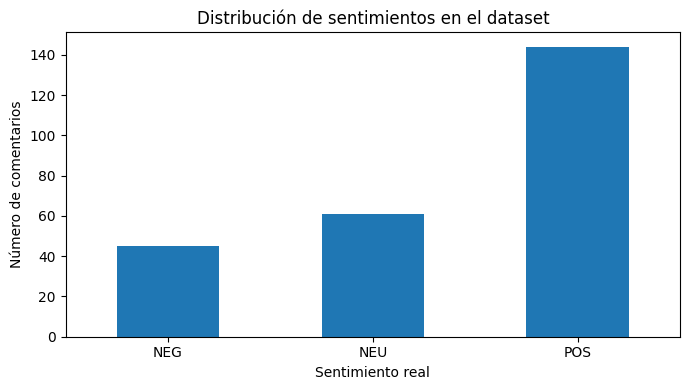

In [12]:
# Visualizar la distribución de clases  

orden = ["NEG", "NEU", "POS"]

conteo = (
    df["label_real"]
    .value_counts()
    .reindex(orden, fill_value=0)
)

plt.figure(figsize=(7, 4))
conteo.plot(kind="bar")
plt.title("Distribución de sentimientos en el dataset")
plt.xlabel("Sentimiento real")
plt.ylabel("Número de comentarios")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [13]:
# Definición de los modelos

MODELOS = {
    "RoBERTuito": (
        "pysentimiento/robertuito-sentiment-analysis"
    ),
    "DistilBERT multilingüe": (
        "lxyuan/distilbert-base-multilingual-cased-sentiments-student"
    ),
    "XLM-RoBERTa": (
        "cardiffnlp/twitter-xlm-roberta-base-sentiment"
    )
}

print("Modelos que se evaluarán:")
for nombre, identificador in MODELOS.items():
    print(f"- {nombre}: {identificador}")


Modelos que se evaluarán:
- RoBERTuito: pysentimiento/robertuito-sentiment-analysis
- DistilBERT multilingüe: lxyuan/distilbert-base-multilingual-cased-sentiments-student
- XLM-RoBERTa: cardiffnlp/twitter-xlm-roberta-base-sentiment


In [14]:
# Carga de modelos y revisión de sus etiquetas

clasificadores = {}
errores_carga = {}

for nombre, identificador in MODELOS.items():
    print(f"\nCargando {nombre}...")

    try:
        clasificador = pipeline(
            task="text-classification",
            model=identificador,
            device=device
        )

        clasificadores[nombre] = clasificador

        print("Etiquetas:", clasificador.model.config.id2label)

    except Exception as e:
        errores_carga[nombre] = str(e)
        print(f"Error al cargar {nombre}: {e}")

if not clasificadores:
    raise RuntimeError(
        "No se pudo cargar ningún modelo. "
        "Revisa la conexión, las dependencias y los errores anteriores."
    )

print("\nModelos cargados:", list(clasificadores.keys()))



Cargando RoBERTuito...


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Etiquetas: {0: 'NEG', 1: 'NEU', 2: 'POS'}

Cargando DistilBERT multilingüe...


config.json:   0%|          | 0.00/759 [00:00<?, ?B/s]

c:\Users\haaal\anaconda3\envs\FaseII\Lib\site-packages\huggingface_hub\file_download.py:138: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\haaal\.cache\huggingface\hub\models--lxyuan--distilbert-base-multilingual-cased-sentiments-student. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


...

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.11G [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/150 [00:00<?, ?B/s]

Etiquetas: {0: 'negative', 1: 'neutral', 2: 'positive'}

Modelos cargados: ['RoBERTuito', 'DistilBERT multilingüe', 'XLM-RoBERTa']


In [15]:
# Inferencia y medición del modelo

def normalizar_prediccion(etiqueta, clasificador):
    etiqueta_original = str(etiqueta).strip()
    etiqueta = etiqueta_original.upper()

    equivalencias = {
        "NEG": "NEG",
        "NEGATIVE": "NEG",
        "NEGATIVO": "NEG",
        "NEU": "NEU",
        "NEUTRAL": "NEU",
        "NEUTRO": "NEU",
        "POS": "POS",
        "POSITIVE": "POS",
        "POSITIVO": "POS"
    }

    if etiqueta in equivalencias:
        return equivalencias[etiqueta]

    # Resolver etiquetas genéricas como LABEL_0
    if etiqueta.startswith("LABEL_"):
        try:
            indice = int(etiqueta.split("_")[-1])
            etiqueta_config = clasificador.model.config.id2label.get(
                indice,
                clasificador.model.config.id2label.get(str(indice), "")
            )
            return normalizar_prediccion(etiqueta_config, clasificador)
        except (ValueError, TypeError):
            pass

    raise ValueError(
        f"No se reconoce la etiqueta '{etiqueta_original}'. "
        "Revisa la configuración del modelo."
    )


In [16]:
# Ejecución de los 3 modelos

textos = df["comentario"].tolist()
labels_reales = df["label_real"].tolist()

resultados_prediccion = {}
registros_tiempo = []

for nombre, clasificador in clasificadores.items():
    print(f"\nEvaluando {nombre}...")

    inicio = time.perf_counter()

    predicciones = clasificador(
        textos,
        batch_size=16,
        truncation=True
    )

    fin = time.perf_counter()

    tiempo_total = fin - inicio
    tiempo_promedio = tiempo_total / len(textos)

    labels_predichos = [
        normalizar_prediccion(p["label"], clasificador)
        for p in predicciones
    ]

    resultados_prediccion[nombre] = {
        "labels": labels_predichos,
        "scores": [float(p["score"]) for p in predicciones]
    }

    registros_tiempo.append({
        "Modelo": nombre,
        "Tiempo total (s)": tiempo_total,
        "Tiempo promedio (s)": tiempo_promedio,
        "Comentarios por segundo": (
            len(textos) / tiempo_total if tiempo_total > 0 else np.nan
        )
    })

    print(f"Comentarios procesados: {len(predicciones)}")
    print(f"Tiempo total: {tiempo_total:.2f} s")
    print(f"Tiempo promedio: {tiempo_promedio:.4f} s/comentario")

df_tiempos = pd.DataFrame(registros_tiempo)
display(df_tiempos.round(4))



Evaluando RoBERTuito...
Comentarios procesados: 250
Tiempo total: 4.33 s
Tiempo promedio: 0.0173 s/comentario

Evaluando DistilBERT multilingüe...
Comentarios procesados: 250
Tiempo total: 2.16 s
Tiempo promedio: 0.0086 s/comentario

Evaluando XLM-RoBERTa...
Comentarios procesados: 250
Tiempo total: 4.02 s
Tiempo promedio: 0.0161 s/comentario


,Modelo,Tiempo total (s),Tiempo promedio (s),Comentarios por segundo
0,RoBERTuito,4.3319,0.0173,57.7108
1,DistilBERT multilingüe,2.1568,0.0086,115.9106
2,XLM-RoBERTa,4.0178,0.0161,62.2231


In [17]:
# Evaluación de los modelos con métricas estándar

resultados_metricas = []

for nombre, resultado in resultados_prediccion.items():
    y_pred = resultado["labels"]

    resultados_metricas.append({
        "Modelo": nombre,
        "Accuracy": accuracy_score(labels_reales, y_pred),
        "Precision macro": precision_score(
            labels_reales, y_pred,
            labels=orden, average="macro", zero_division=0
        ),
        "Recall macro": recall_score(
            labels_reales, y_pred,
            labels=orden, average="macro", zero_division=0
        ),
        "F1 macro": f1_score(
            labels_reales, y_pred,
            labels=orden, average="macro", zero_division=0
        ),
        "Precision weighted": precision_score(
            labels_reales, y_pred,
            labels=orden, average="weighted", zero_division=0
        ),
        "Recall weighted": recall_score(
            labels_reales, y_pred,
            labels=orden, average="weighted", zero_division=0
        ),
        "F1 weighted": f1_score(
            labels_reales, y_pred,
            labels=orden, average="weighted", zero_division=0
        )
    })

df_metricas = pd.DataFrame(resultados_metricas)

display(
    df_metricas.sort_values("F1 macro", ascending=False)
    .round(4)
    .reset_index(drop=True)
)


,Modelo,Accuracy,Precision macro,Recall macro,F1 macro,Precision weighted,Recall weighted,F1 weighted
0,XLM-RoBERTa,0.852,0.9106,0.7978,0.8064,0.8779,0.852,0.8269
1,DistilBERT multilingüe,0.820,0.9147,0.7541,0.7574,0.8613,0.820,0.7791
2,RoBERTuito,0.768,0.9043,0.6831,0.6420,0.8346,0.768,0.6823


In [18]:
# Informe detallado por modelo


for nombre, resultado in resultados_prediccion.items():
    print("\n" + "=" * 60)
    print(f"INFORME DE CLASIFICACIÓN: {nombre}")
    print("=" * 60)

    print(classification_report(
        labels_reales,
        resultado["labels"],
        labels=orden,
        target_names=["Negativo", "Neutral", "Positivo"],
        digits=4,
        zero_division=0
    ))



INFORME DE CLASIFICACIÓN: RoBERTuito
              precision    recall  f1-score   support

    Negativo     1.0000    1.0000    1.0000        45
     Neutral     1.0000    0.0492    0.0938        61
    Positivo     0.7129    1.0000    0.8324       144

    accuracy                         0.7680       250
   macro avg     0.9043    0.6831    0.6420       250
weighted avg     0.8346    0.7680    0.6823       250


INFORME DE CLASIFICACIÓN: DistilBERT multilingüe
              precision    recall  f1-score   support

    Negativo     0.9783    1.0000    0.9890        45
     Neutral     1.0000    0.2623    0.4156        61
    Positivo     0.7660    1.0000    0.8675       144

    accuracy                         0.8200       250
   macro avg     0.9147    0.7541    0.7574       250
weighted avg     0.8613    0.8200    0.7791       250


INFORME DE CLASIFICACIÓN: XLM-RoBERTa
              precision    recall  f1-score   support

    Negativo     0.9184    1.0000    0.9574        45
  

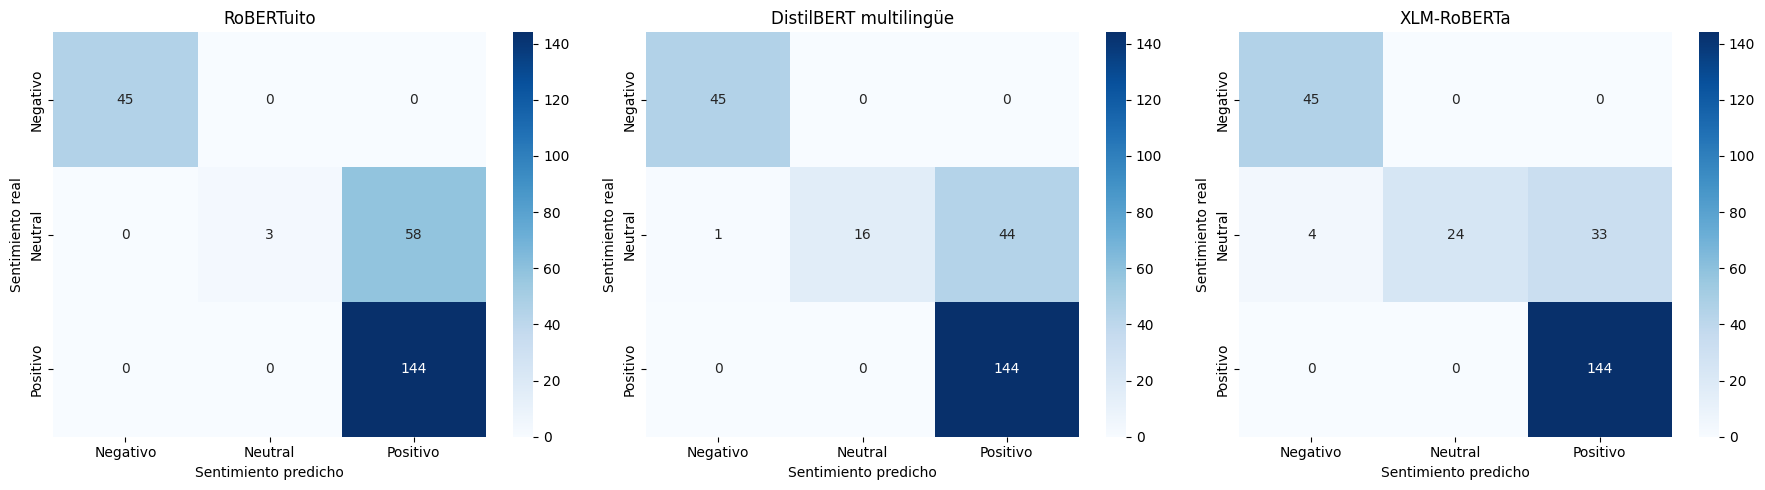

In [19]:
#Matrices de confusión

fig, axes = plt.subplots(
    1, len(resultados_prediccion),
    figsize=(6 * len(resultados_prediccion), 5)
)

axes = np.atleast_1d(axes)

for ax, (nombre, resultado) in zip(
    axes, resultados_prediccion.items()
):
    cm = confusion_matrix(
        labels_reales,
        resultado["labels"],
        labels=orden
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Negativo", "Neutral", "Positivo"],
        yticklabels=["Negativo", "Neutral", "Positivo"],
        ax=ax
    )

    ax.set_title(nombre)
    ax.set_xlabel("Sentimiento predicho")
    ax.set_ylabel("Sentimiento real")

plt.tight_layout()
plt.show()


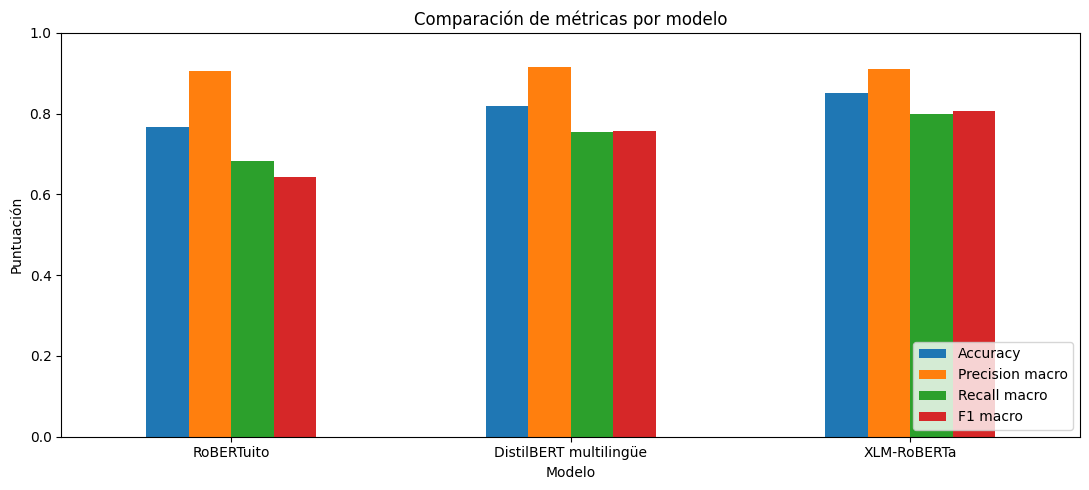

In [ ]:
# Comparación de desempeño y eficiencia

metricas_grafica = [
    "Accuracy",
    "Precision macro",
    "Recall macro",
    "F1 macro"
]

df_grafica = df_metricas.set_index("Modelo")[metricas_grafica]

ax = df_grafica.plot(
    kind="bar",
    figsize=(11, 5),
    ylim=(0, 1),
    rot=0
)

ax.set_title("Comparación de métricas por modelo")
ax.set_ylabel("Puntuación")
ax.set_xlabel("Modelo")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()


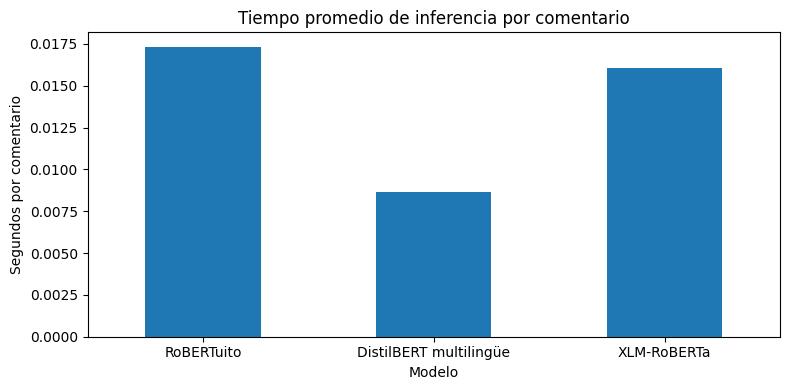

,Modelo,Tiempo total (s),Tiempo promedio (s),Comentarios por segundo
1,DistilBERT multilingüe,2.1568,0.0086,115.9106
2,XLM-RoBERTa,4.0178,0.0161,62.2231
0,RoBERTuito,4.3319,0.0173,57.7108


In [21]:
# Comparación de velocidad de inferencia

df_tiempos.plot(
    x="Modelo",
    y="Tiempo promedio (s)",
    kind="bar",
    figsize=(8, 4),
    legend=False,
    rot=0
)

plt.title("Tiempo promedio de inferencia por comentario")
plt.ylabel("Segundos por comentario")
plt.xlabel("Modelo")
plt.tight_layout()
plt.show()

display(
    df_tiempos.sort_values(
        "Tiempo promedio (s)"
    ).round(4)
)


In [22]:
# Selección automática del mejor modelo

comparacion = df_metricas.merge(
    df_tiempos,
    on="Modelo",
    how="inner"
)

comparacion = comparacion.sort_values(
    by=["F1 macro", "Tiempo promedio (s)"],
    ascending=[False, True]
).reset_index(drop=True)

display(comparacion.round(4))

mejor_modelo = comparacion.iloc[0]["Modelo"]

print("Mejor modelo según F1 macro:", mejor_modelo)
print(
    "F1 macro:",
    round(comparacion.iloc[0]["F1 macro"], 4)
)
print(
    "Tiempo promedio:",
    round(comparacion.iloc[0]["Tiempo promedio (s)"], 4),
    "segundos por comentario"
)


,Modelo,Accuracy,Precision macro,Recall macro,F1 macro,Precision weighted,Recall weighted,F1 weighted,Tiempo total (s),Tiempo promedio (s),Comentarios por segundo
0,XLM-RoBERTa,0.852,0.9106,0.7978,0.8064,0.8779,0.852,0.8269,4.0178,0.0161,62.2231
1,DistilBERT multilingüe,0.820,0.9147,0.7541,0.7574,0.8613,0.820,0.7791,2.1568,0.0086,115.9106
2,RoBERTuito,0.768,0.9043,0.6831,0.6420,0.8346,0.768,0.6823,4.3319,0.0173,57.7108


Mejor modelo según F1 macro: XLM-RoBERTa
F1 macro: 0.8064
Tiempo promedio: 0.0161 segundos por comentario


In [23]:
# Inspección de ejemplos con predicciones erróneas

df_comparacion = df.copy()

for nombre, resultado in resultados_prediccion.items():
    df_comparacion[f"Predicción - {nombre}"] = (
        resultado["labels"]
    )
    df_comparacion[f"Confianza - {nombre}"] = (
        resultado["scores"]
    )

columnas_predicciones = [
    f"Predicción - {nombre}"
    for nombre in resultados_prediccion
]

df_comparacion["Desacuerdo"] = df_comparacion[
    columnas_predicciones
].nunique(axis=1) > 1

columnas_mostrar = [
    columna for columna in [
        "comentario",
        "aspecto",
        "calificacion",
        "label_real"
    ] if columna in df_comparacion.columns
] + columnas_predicciones

display(
    df_comparacion.loc[
        df_comparacion["Desacuerdo"],
        columnas_mostrar
    ].head(20)
)


,comentario,aspecto,calificacion,label_real,Predicción - RoBERTuito,Predicción - DistilBERT multilingüe,Predicción - XLM-RoBERTa
18,"La comida fue aceptable, podría mejorar. (menc...",comida,3,NEU,POS,POS,NEU
20,"La servicio estuvo regular, cumplió sin destac...",servicio,3,NEU,POS,NEU,NEU
50,"La servicio estuvo regular, cumplió sin destac...",servicio,3,NEU,POS,NEU,NEU
64,"La comida fue aceptable, podría mejorar. (menc...",comida,3,NEU,POS,POS,NEU
70,"La ambiente estuvo regular, cumplió sin destac...",ambiente,3,NEU,POS,NEU,NEG
75,"La ambiente estuvo bien, nada fuera de lo norm...",ambiente,3,NEU,POS,POS,NEU
80,"La comida fue aceptable, podría mejorar. (menc...",comida,3,NEU,POS,POS,NEU
83,"La comida fue aceptable, podría mejorar. (menc...",comida,3,NEU,POS,POS,NEU
97,"La comida fue aceptable, podría mejorar. (menc...",comida,3,NEU,POS,POS,NEU
98,"La comida estuvo regular, cumplió sin destacar...",comida,3,NEU,POS,NEU,NEU
